In [52]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report,f1_score,recall_score,precision_score


data=load_breast_cancer()
X=pd.DataFrame(data.data,columns=data.feature_names)
y=data.target

print("FEATURES:",X.head())
print("TARGET CLASSES:",data.target_names)
print("DATASET SHAPES:",X.shape)


FEATURES:    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0 

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42))
])

model.fit(X_train,y_train)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)
print(train_pred)
print(test_pred)

[1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 0 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0 0 0
 1 0 1 1 1 0 1 1 1 1 0 1 0 0 0 1 1 1 1 1 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0
 1 1 1 1 1 0 0 0 0 0 1 1 0 0 1 0 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1 1 1 0 1 1 1
 0 0 0 1 1 1 0 0 1 1 1 1 0 1 0 0 1 0 1 1 1 0 1 1 0 1 0 1 1 0 1 1 0 1 1 1 0
 1 0 1 1 1 0 0 1 1 0 1 1 0 1 1 1 0 1 0 0 0 0 1 0 0 1 0 1 1 1 1 1 1 1 1 1 1
 0 1 1 1 1 1 1 1 1 0 1 1 0 0 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1
 1 1 1 0 1 0 0 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 1 1 1 0 0 1 1 0 0 0 1 1 0
 0 0 1 1 1 0 1 1 1 1 1 1 0 0 1 1 1 0 0 0 1 1 1 0 1 0 0 1 0 1 1 1 0 1 1 1 0
 0 0 0 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 0 0 1 1 1 1 1 1 1 0
 1 0 1 1 1 1 0 1 1 0 0 1 1 1 0 1 1 0 1 0 0 1 1 0 0 0 1 1 1 1 1 1 0 0 1 1 1
 0 1 0 1 0 0 1 1 1 1 1 0 1 1 1 0 0 1 1 1 0 1 0 1 0 1 1 0 0 1 1 1 1 0 1 0 1
 1 1 0 1 1 1 0 1 0 0 0 1 1 1 1 0 0 0 1 0 1 1 1 0 0 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 0 0 0 0 0 1]
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 0 0 1
 

In [44]:
test_prob=model.predict_proba(X_test)[:,0]
print(test_prob)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)
print("train accuracy:",train_accuracy)
print("test accuracy:",test_accuracy)


[1.        0.0112782 0.9047619 0.4       1.        0.0112782 0.0112782
 1.        1.        1.        0.0112782 1.        0.0112782 1.
 1.        0.0112782 0.0112782 0.0112782 0.0112782 0.0112782 1.
 0.4       0.0112782 0.0112782 0.0112782 1.        1.        0.0112782
 0.0112782 0.0112782 0.25      0.0112782 0.0112782 0.0112782 1.
 0.9047619 0.0112782 0.4       0.25      1.        0.0112782 0.0112782
 0.0112782 1.        1.        0.25      0.0112782 0.0112782 1.
 1.        0.0112782 0.0112782 0.0112782 0.25      0.0112782 0.0112782
 0.0112782 1.        1.        0.0112782 0.0112782 0.0112782 0.0112782
 0.0112782 1.        0.0112782 0.9047619 0.0112782 0.0112782 0.25
 0.0112782 0.0112782 0.0112782 1.        1.        1.        0.9047619
 0.0112782 0.0112782 0.0112782 0.0112782 0.0112782 1.        0.0112782
 0.        0.0112782 0.0112782 0.0112782 0.0112782 0.0112782 0.25
 0.0112782 1.        1.        1.        0.0112782 1.        0.0112782
 1.        0.0112782 1.        1.        0.9

In [53]:

accuracy = accuracy_score(y_test, test_pred)

precision = precision_score(y_test, test_pred, pos_label=0)

recall = recall_score(y_test, test_pred, pos_label=0)

f1 = f1_score(y_test, test_pred, pos_label=0)
print("Accuracy:", accuracy)
print("Precision :", precision)
print("Recall :", recall)
print("F1 Score :", f1)


print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_pred,
        target_names=data.target_names,
        zero_division=0
    )
)
cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)


Accuracy: 0.9385964912280702
Precision : 0.926829268292683
Recall : 0.9047619047619048
F1 Score : 0.9156626506024096

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


Confusion Matrix:
[[38  4]
 [ 3 69]]



Top 10 Important Features:
worst radius            0.765578
worst concave points    0.127356
texture error           0.047784
worst texture           0.033731
worst concavity         0.017911
area error              0.007641
mean radius             0.000000
concavity error         0.000000
worst symmetry          0.000000
worst compactness       0.000000
dtype: float64


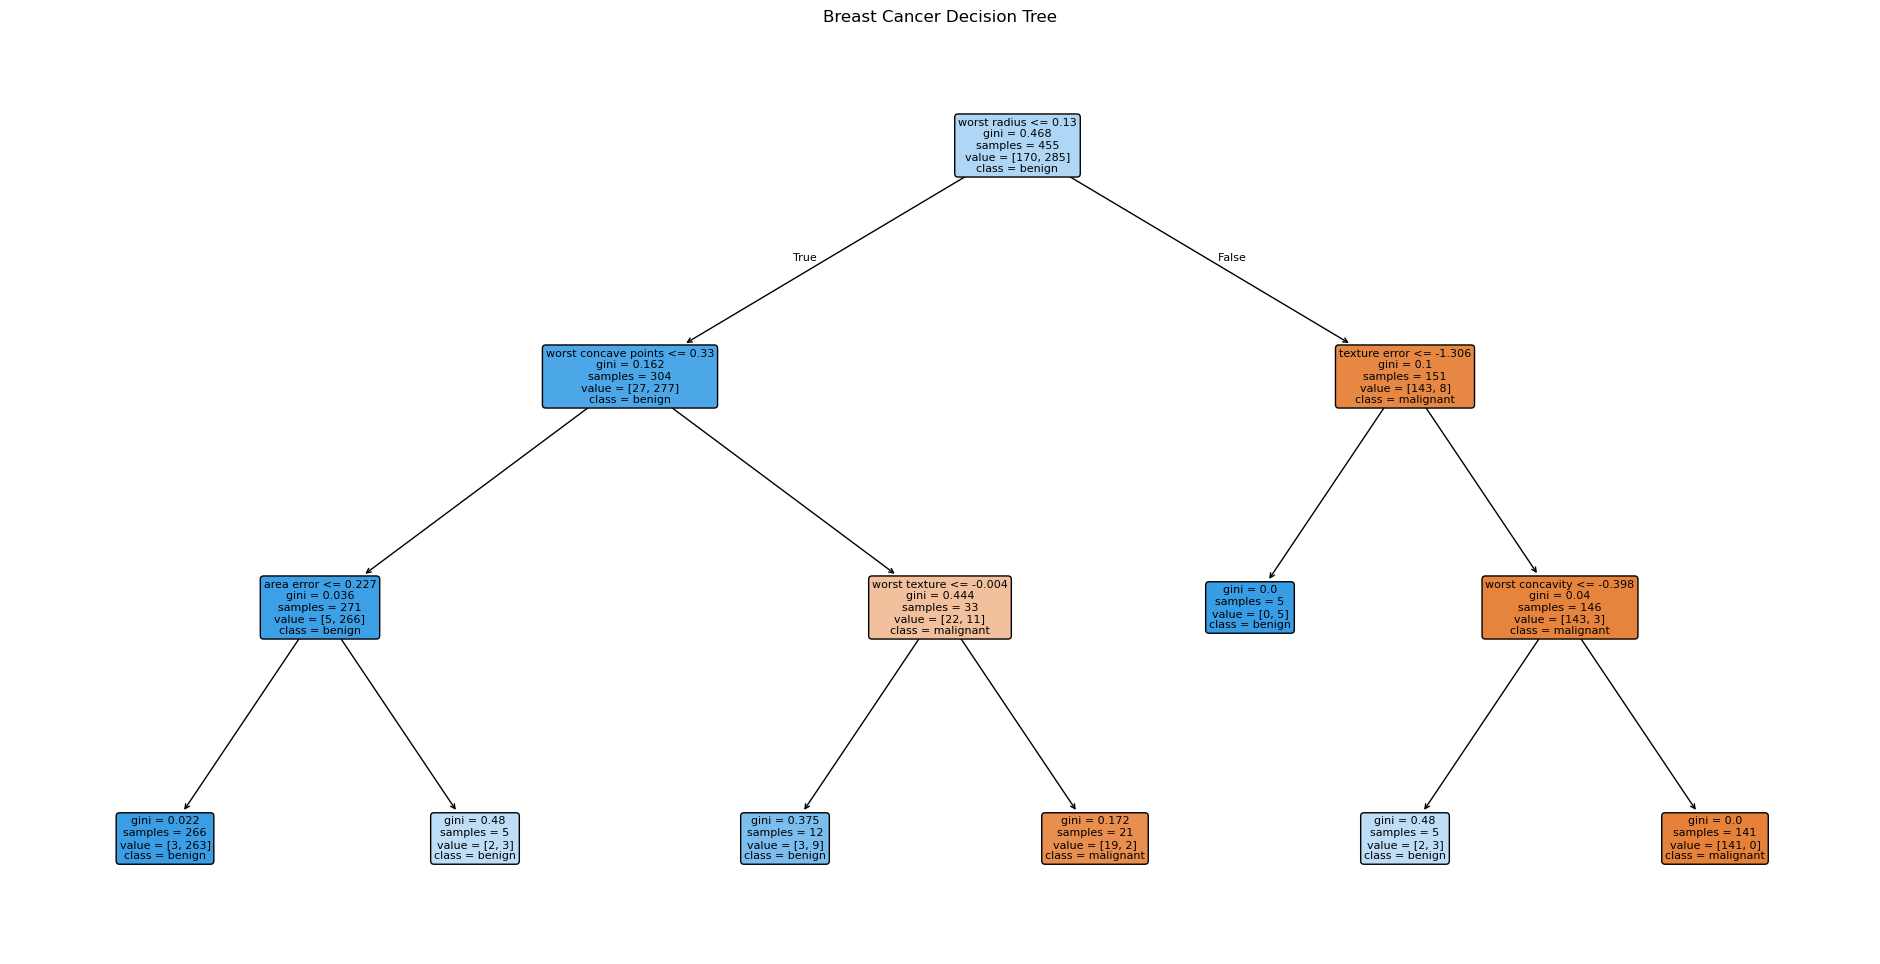

In [59]:
tree = model.named_steps["classifier"]   

importance = pd.Series(
    tree.feature_importances_,
    index=data.feature_names
).sort_values(ascending=False)

print("\nTop 10 Important Features:")
print(importance.head(10))


plt.figure(figsize=(24, 12))
plot_tree(
    tree,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Breast Cancer Decision Tree")
plt.show()